Setup → Count → LOOK at images → measure sizes → check modes
      → check pixel stats → find corrupt files → verify labels

In [1]:
import os,random
import numpy as np
import matplotlib.pyplot as plt
#PIL is used to open and decode files(.jpg)
from PIL import Image
from collections import Counter

BASE = "PetImages"
CLASSES = ["Cat","Dog"]

{'Cat': 12499, 'Dog': 12499}


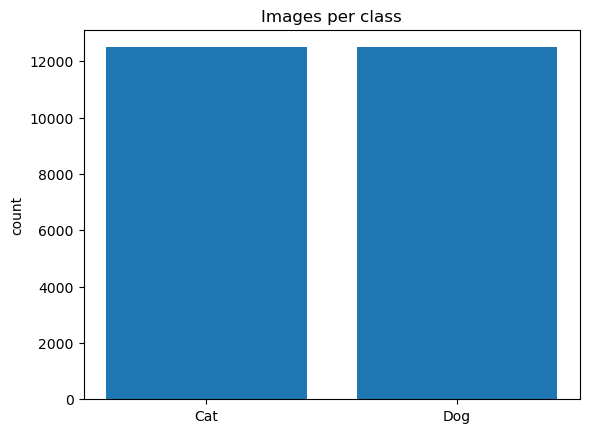

In [2]:
counts = {c: len(os.listdir(os.path.join(BASE, c))) for c in CLASSES}
print(counts)

plt.bar(counts.keys(), counts.values())
plt.title("Images per class")
plt.ylabel("count")
plt.show()

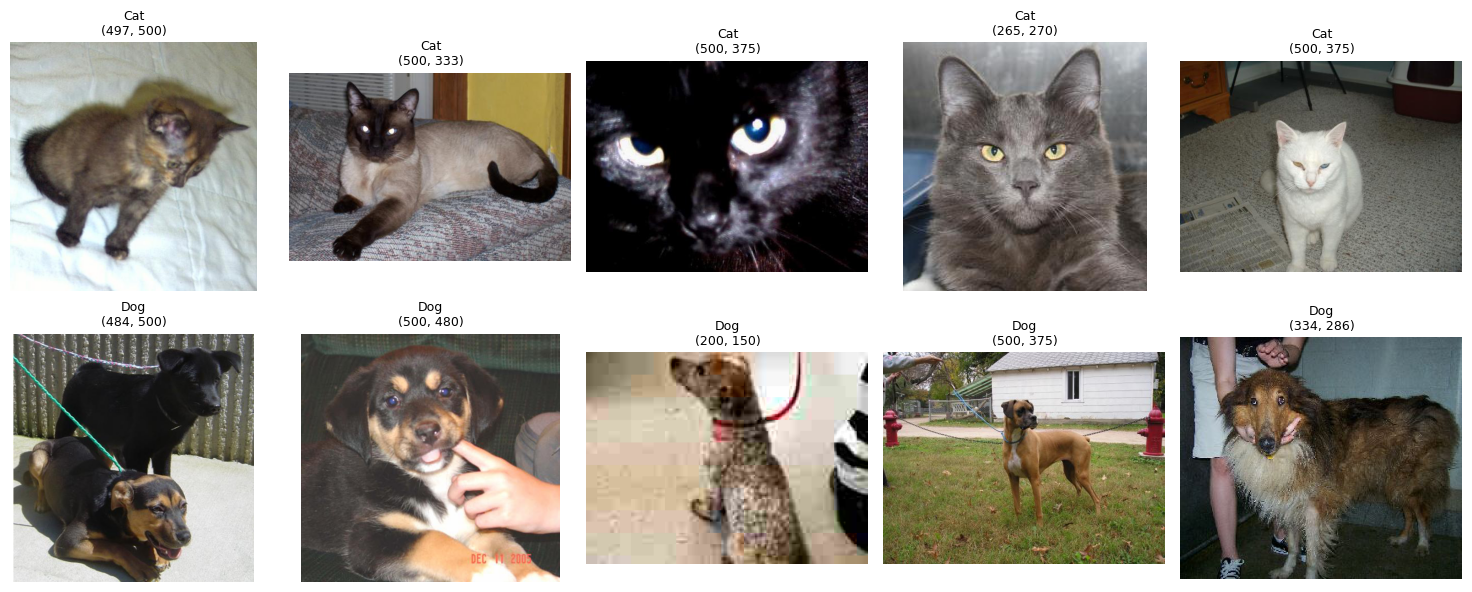

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, cls in enumerate(CLASSES):
    folder = os.path.join(BASE, cls)
    files = random.sample(os.listdir(folder), 5)
    for j, f in enumerate(files):
        img = Image.open(os.path.join(folder, f)).convert("RGB")
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"{cls}\n{img.size}", fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

width  min/med/max: 100 475 500
height min/med/max: 100 375 500


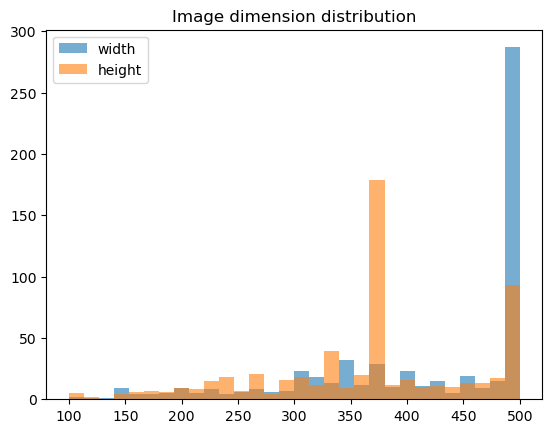

In [4]:
sizes = []
for cls in CLASSES:
    for f in random.sample(os.listdir(os.path.join(BASE, cls)), 300):
        with Image.open(os.path.join(BASE, cls, f)) as im:
            sizes.append(im.size)

w, h = zip(*sizes)
print("width  min/med/max:", min(w), int(np.median(w)), max(w))
print("height min/med/max:", min(h), int(np.median(h)), max(h))

plt.hist(w, bins=30, alpha=0.6, label="width")
plt.hist(h, bins=30, alpha=0.6, label="height")
plt.legend(); plt.title("Image dimension distribution"); plt.show()

In [5]:
modes = Counter()
for cls in CLASSES:
    for f in random.sample(os.listdir(os.path.join(BASE, cls)), 300):
        with Image.open(os.path.join(BASE, cls, f)) as im:
            modes[im.mode] += 1
print(modes)

Counter({'RGB': 598, 'P': 2})


In [ ]:
'''
Open 100 random images per class, force them to RGB and 64×64 so they're all the same shape, 
scale pixels to 0–1, collapse each image to its average color (3 numbers), then average across 
all images to get the dataset's typical RGB
'''
pixels = []
for cls in CLASSES:
    for f in random.sample(os.listdir(os.path.join(BASE, cls)), 100):
        im = np.array(
            Image.open(os.path.join(BASE, cls, f))
            .convert("RGB")
            .resize((64, 64))
        ) / 255.0
        pixels.append(im.mean(axis=(0, 1)))
pixels = np.array(pixels)
print("mean RGB:", pixels.mean(axis=0))

mean RGB: [0.48699682 0.4519161  0.41294593]


In [7]:
def find_bad(folder):
    bad = []
    for f in os.listdir(folder):
        try:
            with Image.open(os.path.join(folder, f)) as im:
                im.verify()
        except Exception:
            bad.append(f)
    return bad

for cls in CLASSES:
    b = find_bad(os.path.join(BASE, cls))
    print(cls, "bad:", b)

Cat bad: []
Dog bad: []


c:\Users\aahan\anaconda3\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


In [8]:
for cls in CLASSES:
    print(cls, os.listdir(os.path.join(BASE, cls))[:3])

Cat ['0.jpg', '1.jpg', '10.jpg']
Dog ['0.jpg', '1.jpg', '10.jpg']
